# Read in all Result csv tables 

In [57]:
import pandas as pd
from pathlib import Path
import src.read_write as read_write

dir_distortion_metrics = Path('data/all_distortion_metrics')

dfs = []

for file in dir_distortion_metrics.iterdir():
    if "position" in file.name:

        for subfile in file.iterdir():
            if ".csv" in subfile.name:

                position, technique, order = read_write.extract_position_technique_and_order(file)

                df = pd.read_csv(subfile)

                # Add parent folder name as a new column
                df["name"] = file.name

                df["position"] = position
                df["technique"] = technique
                df["order"] = order

                dfs.append(df)

# Combine all CSVs into one dataframe
df_all_raw = pd.concat(dfs, ignore_index=True)


# Desired order of the first columns
first_cols = ["name", "position", "technique", "order"]

# Append all remaining columns in their current order
df_all_raw = df_all_raw[first_cols + [col for col in df_all_raw.columns if col not in first_cols]]
#df_all_raw.to_csv("all_distortion_raw.csv", index=False)

df_all = df_all_raw.copy()

# Custom technique order
technique_order = [
    "IFFT",
    "CPROne",
    "CPRIter",
    "IDC",
    "IROC",
]

df_all["technique"] = pd.Categorical(
    df_all["technique"],
    categories=technique_order,
    ordered=True,
)

# Ensure order is numeric
df_all["order"] = pd.to_numeric(df_all["order"], errors="coerce")

# Sort
df_all = df_all.sort_values(
    by=["position","label", "technique", "order"],
    na_position="last",
).reset_index(drop=True)


#df_all.to_csv("all_distortion_metrics.csv", index=False)
#df_all

# ---- Keep only Control Scan (ROreg_ES000) ----
df_reg000 = df_all[
    df_all["name"].str.contains("ROreg_ES000", na=False)
].reset_index(drop=True)


#df_reg000.to_csv("all_distortion_metrics_reg000.csv", index=False)
df_reg000


,name,position,technique,order,label,n_voxels,mean,std,min,max
0,position0_ROreg_ES000_IFFT_OrderNA,0,IFFT,NaN,0,1503487,2.677506,1.195047,0.000297,17.109171
1,position0_ROreg_ES000_CPROne_Order02,0,CPROne,2.0,0,1503487,2.509223,1.063347,0.003020,16.598917
2,position0_ROreg_ES000_CPROne_Order04,0,CPROne,4.0,0,1503487,2.483552,1.030372,0.002549,16.506767
3,position0_ROreg_ES000_CPROne_Order08,0,CPROne,8.0,0,1503487,2.493250,1.021098,0.001941,16.052545
4,position0_ROreg_ES000_CPROne_Order12,0,CPROne,12.0,0,1503487,2.492827,1.021031,0.001974,16.084450
...,...,...,...,...,...,...,...,...,...,...
387,position3_ROreg_ES000_IDC_OrderNA,3,IDC,NaN,6,1322742,2.743617,1.564621,0.008844,8.874577
388,position3_ROreg_ES000_IROC_Order02,3,IROC,2.0,6,1322742,2.890912,1.785180,0.008048,11.092857
389,position3_ROreg_ES000_IROC_Order04,3,IROC,4.0,6,1322742,2.769783,1.679725,0.008242,10.460993
390,position3_ROreg_ES000_IROC_Order08,3,IROC,8.0,6,1322742,2.694002,1.652429,0.012038,9.671585


# CHOSE BEST PERFORMER SSH and Clean Up
- CPROne    keep order 04
- CORIter   keep Order 04
- IROC      keep Order 12

- Remove min, n_voxels, and name
- Delete label 6 
- Rename Labels
- Rearrange (Pivot)

In [58]:

# ========================================================================================================
# ========================== Filter the best Performer ====================================================
# ========================================================================================================


SSH_techniques = ["CPROne", "CPRIter", "IROC"]
best_performer = ["Order04", "Order04", "Order12"]

# ========================================================================================================

patterns = [
    f"{technique}_{order}"
    for technique, order in zip(SSH_techniques, best_performer)
]

pattern = r"IFFT|IDC|" + "|".join(patterns)

df_reg000_best_order = df_reg000[
    df_reg000["name"].str.contains(
        pattern,
        na=False
    )
].reset_index(drop=True)



#df_reg000_best_order.to_csv("all_distortion_metrics_reg000_best_order.csv", index=False)

# ----- Remove min and n_voxels ----
df_reg000_best_order_clean = df_reg000_best_order.drop(columns=["min", "n_voxels","name","order"])
# ---- Remove label 6 ----
df_reg000_best_order_clean =  df_reg000_best_order_clean[df_reg000_best_order_clean["label"] != 6]
# ---- Rename Labels ----
label_names = {
    0: "Full Phantom",
    1: "Big Ring",
    2: "Boxes",
    3: "Cylinders",
    4: "Grid",
    5: "Indents"
}
df_reg000_best_order_clean["label"] = df_reg000_best_order_clean["label"].map(label_names)

# ---- Round Data to 2 Decimal Places ----
df_reg000_best_order_clean[["mean", "std", "max"]] = (df_reg000_best_order_clean[["mean", "std", "max"]].round(2))

# ---- Rearrange -----


df_pivot = df_reg000_best_order_clean.pivot(
    index=["label", "technique"],
    columns="position",
    values=["mean", "std", "max"]
)

df_pivot.columns = [
    f"{position}_{metric}"
    for metric, position in df_pivot.columns
]

df_pivot = df_pivot.reset_index()

# Reorder position columns: 1, 2, 3, 0
fixed_cols = ["label", "technique"]
position_cols = [
    f"{p}_{m}"
    for p in ["1", "2", "3", "0"]
    for m in ["mean", "std", "max"]
]

df_pivot = df_pivot[fixed_cols + position_cols]

df_pivot = pd.concat([
    df_pivot[df_pivot["label"] != "Full Phantom"],
    df_pivot[df_pivot["label"] == "Full Phantom"]
]).reset_index(drop=True)

df_pivot

,label,technique,1_mean,1_std,1_max,2_mean,2_std,2_max,3_mean,3_std,3_max,0_mean,0_std,0_max
0,Big Ring,IFFT,1.55,0.99,4.55,1.33,0.67,3.98,4.71,2.27,11.28,2.53,0.90,11.28
1,Big Ring,CPROne,1.35,0.79,3.56,1.27,0.62,3.71,4.56,2.05,10.59,2.39,0.82,10.59
2,Big Ring,CPRIter,1.12,0.59,3.07,1.15,0.56,3.33,4.39,1.78,9.85,2.22,0.73,9.85
3,Big Ring,IDC,2.85,2.34,9.13,1.59,0.51,4.05,3.91,1.61,7.60,2.78,1.16,9.13
4,Big Ring,IROC,0.84,0.29,1.59,1.04,0.56,3.01,3.94,1.34,6.72,1.94,0.61,6.72
5,Boxes,IFFT,3.65,1.45,8.10,1.85,0.95,6.87,2.10,0.88,4.78,2.53,0.76,8.10
6,Boxes,CPROne,3.47,1.31,8.25,1.68,0.92,6.89,1.94,0.76,5.14,2.36,0.73,8.25
7,Boxes,CPRIter,3.26,1.18,8.26,1.51,0.90,6.96,1.63,0.67,5.57,2.13,0.73,8.26
8,Boxes,IDC,8.25,2.90,16.66,2.99,1.30,9.59,3.16,1.14,7.18,4.80,1.46,16.66
9,Boxes,IROC,2.29,1.21,8.41,1.50,0.80,6.68,1.12,0.77,6.05,1.64,0.87,8.41


# Ranking Amongst Techniques

In [59]:
# Remove Full Phantom
df_pivot = df_pivot[df_pivot["label"] != "Full Phantom"].reset_index(drop=True)

# ========================================================================================================
# =================================== Ranking ============================================================
# ========================================================================================================

import pandas as pd

metrics = ["mean", "std", "max"]
positions = ["1", "2", "3", "0"]

df_ranking = df_pivot.copy()

for position in positions:
    for metric in metrics:

        col = f"{position}_{metric}"

        # Lowest value = rank 1
        df_ranking[col] = (
            df_ranking
            .groupby("label")[col]
            .rank(method="min", ascending=True)
            .astype(int)
        )

# Sort techniques within each label
df_ranking = df_ranking.sort_values(
    ["label", "technique"]
).reset_index(drop=True)

df_ranking

,label,technique,1_mean,1_std,1_max,2_mean,2_std,2_max,3_mean,3_std,3_max,0_mean,0_std,0_max
0,Big Ring,IFFT,4,4,4,4,5,4,5,5,5,4,4,5
1,Big Ring,CPROne,3,3,3,3,4,3,4,4,4,3,3,4
2,Big Ring,CPRIter,2,2,2,2,2,2,3,3,3,2,2,3
3,Big Ring,IDC,5,5,5,5,1,5,1,2,2,5,5,2
4,Big Ring,IROC,1,1,1,1,2,1,2,1,1,1,1,1
5,Boxes,IFFT,4,4,1,4,4,2,4,4,1,4,3,1
6,Boxes,CPROne,3,3,2,3,3,3,3,2,2,3,1,2
7,Boxes,CPRIter,2,1,3,2,2,4,2,1,3,2,1,3
8,Boxes,IDC,5,5,5,5,5,5,5,5,5,5,5,5
9,Boxes,IROC,1,2,4,1,1,1,1,3,4,1,4,4


In [60]:
# ========================================================================================================
# ============================== Summary ranking =========================================================
# ========================================================================================================

techniques = df_ranking["technique"].unique()

ranking_summary = []

for technique in techniques:

    row = {"technique": technique}

    for metric in metrics:

        cols = [f"{p}_{metric}" for p in positions]

        values = df_ranking.loc[
            df_ranking["technique"] == technique,
            cols
        ].values.flatten()

        total = len(values)

        # Number of techniques being ranked
        n_techniques = df_ranking["technique"].nunique()
        last_rank = n_techniques

        # Count 1st, 2nd and last
        for rank, name in [
            (1, "1st"),
            (2, "2nd"),
            (last_rank, "Last")
        ]:
            count = (values == rank).sum()
            row[f"{metric}_{name}"] = f"{count}/{total}"

        # Average rank
        row[f"{metric}_avg_rank"] = values.mean()

    ranking_summary.append(row)

df_ranking_summary = pd.DataFrame(ranking_summary)

df_ranking_summary

,technique,mean_1st,mean_2nd,mean_Last,mean_avg_rank,std_1st,std_2nd,std_Last,std_avg_rank,max_1st,max_2nd,max_Last,max_avg_rank
0,IFFT,0/20,0/20,10/20,4.50,0/20,0/20,11/20,4.50,3/20,1/20,12/20,4.05
1,CPROne,0/20,0/20,0/20,3.30,1/20,2/20,0/20,3.30,0/20,3/20,0/20,3.30
2,CPRIter,0/20,15/20,0/20,2.25,4/20,8/20,0/20,2.20,1/20,7/20,0/20,2.60
3,IDC,5/20,0/20,10/20,3.70,5/20,4/20,9/20,3.25,3/20,5/20,8/20,3.40
4,IROC,15/20,5/20,0/20,1.25,11/20,6/20,0/20,1.65,13/20,4/20,0/20,1.65


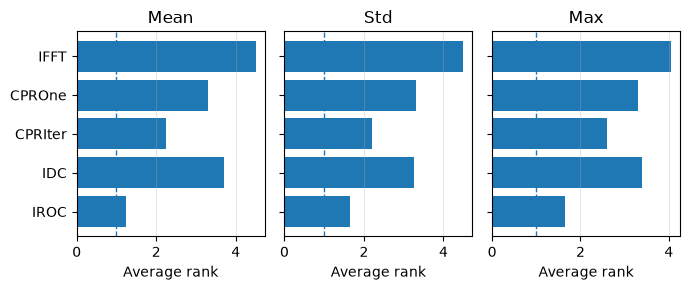

In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Columns containing average ranks
avg_rank_cols = {
    "mean_avg_rank": "Mean",
    "std_avg_rank": "Std",
    "max_avg_rank": "Max"
}

techniques = df_ranking_summary["technique"].tolist()

fig, axes = plt.subplots(
    1, 3,
    figsize=(7, 3),
    sharey=True
)

for ax, (col, title) in zip(axes, avg_rank_cols.items()):

    values = df_ranking_summary[col].values

    y = np.arange(len(techniques))

    ax.barh(y, values)

    ax.set_yticks(y)
    ax.set_yticklabels(techniques)

    ax.set_xlabel("Average rank")
    ax.set_title(title)

    # Lower rank = better
    ax.invert_yaxis()

    # Useful because 1 is the theoretical best
    ax.axvline(1, linestyle="--", linewidth=1)

    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Convert to Latex Tabular

In [62]:


# ---- TO LATEX CODE ----

df = df_pivot.copy()

positions = ["1", "2", "3", "0"]
metrics = ["mean", "std", "max"]

latex_lines = []

# Header
latex_lines.append(r"\begin{tabular}{l|rrr|rrr|rrr|rrr}")
latex_lines.append(
    r"& \multicolumn{3}{c|}{\textbf{Position 1}}"
    r"& \multicolumn{3}{c|}{\textbf{Position 2}}"
    r"& \multicolumn{3}{c|}{\textbf{Position 3}}"
    r"& \multicolumn{3}{c}{\textbf{Positions Combined}} \\"
)
latex_lines.append(r"\hline")

latex_lines.append(
    r"\multicolumn{1}{c|}{\textbf{Recon.}}"
    r"& \multicolumn{1}{c}{\textbf{Mean}}"
    r"& \multicolumn{1}{c}{\textbf{Std}}"
    r"& \multicolumn{1}{c|}{\textbf{Max}}"
    r"& \multicolumn{1}{c}{\textbf{Mean}}"
    r"& \multicolumn{1}{c}{\textbf{Std}}"
    r"& \multicolumn{1}{c|}{\textbf{Max}}"
    r"& \multicolumn{1}{c}{\textbf{Mean}}"
    r"& \multicolumn{1}{c}{\textbf{Std}}"
    r"& \multicolumn{1}{c|}{\textbf{Max}}"
    r"& \multicolumn{1}{c}{\textbf{Mean}}"
    r"& \multicolumn{1}{c}{\textbf{Std}}"
    r"& \multicolumn{1}{c}{\textbf{Max}} \\"
)

latex_lines.append(
    r"\multicolumn{1}{c|}{\textbf{[mm]}}"
    + "".join(
        r"& \multicolumn{1}{c" +
        ("|" if i % 3 == 2 and i < 11 else "") +
        r"}{\textbf{[mm]}}"
        for i in range(12)
    )
    + r" \\"
)

latex_lines.append(r"\hline")

# Labels
for label, group in df.groupby("label", sort=False):

    latex_lines.append(r"\multicolumn{13}{l}{}\\")
    latex_lines.append(
        rf"\multicolumn{{13}}{{c}}{{\textbf{{{label}}}}}\\"
    )

    # Minimum within this label
    mins = {}
    for position in positions:
        for metric in metrics:
            col = f"{position}_{metric}"
            mins[col] = group[col].min()

    # Reconstruction rows
    for _, row in group.iterrows():

        values = []

        for position in positions:
            for metric in metrics:
                col = f"{position}_{metric}"
                value = row[col]

                if pd.isna(value):
                    values.append("")
                elif value == mins[col]:
                    values.append(rf"\textbf{{{value:.2f}}}")
                else:
                    values.append(f"{value:.2f}")

        latex_lines.append(
            f"{row['technique']} & " + " & ".join(values) + r" \\"
        )

latex_lines.append(r"\hline")
latex_lines.append(r"\end{tabular}")
latex_lines.append(
    r"\captionof{table}{Geometric distortion metrics for the evaluated reconstruction methods (IFFT, CPR, Iterative CPR, IROC, and IDC). For techniques relying on a SSH expansion the best performing SSH order was chosen (CPR: Order 4, IROC: Order 12). Distortion was quantified by the mean voxel-wise displacement, its standard deviation, and the maximum observed displacement across six segmentation labels. Results are reported for three scanner positions and For all positions combined.}"
)
latex_lines.append(r"\label{tab_results_all}")

latex = "\n".join(latex_lines)

print(latex)

\begin{tabular}{l|rrr|rrr|rrr|rrr}
& \multicolumn{3}{c|}{\textbf{Position 1}}& \multicolumn{3}{c|}{\textbf{Position 2}}& \multicolumn{3}{c|}{\textbf{Position 3}}& \multicolumn{3}{c}{\textbf{Positions Combined}} \\
\hline
\multicolumn{1}{c|}{\textbf{Recon.}}& \multicolumn{1}{c}{\textbf{Mean}}& \multicolumn{1}{c}{\textbf{Std}}& \multicolumn{1}{c|}{\textbf{Max}}& \multicolumn{1}{c}{\textbf{Mean}}& \multicolumn{1}{c}{\textbf{Std}}& \multicolumn{1}{c|}{\textbf{Max}}& \multicolumn{1}{c}{\textbf{Mean}}& \multicolumn{1}{c}{\textbf{Std}}& \multicolumn{1}{c|}{\textbf{Max}}& \multicolumn{1}{c}{\textbf{Mean}}& \multicolumn{1}{c}{\textbf{Std}}& \multicolumn{1}{c}{\textbf{Max}} \\
\multicolumn{1}{c|}{\textbf{[mm]}}& \multicolumn{1}{c}{\textbf{[mm]}}& \multicolumn{1}{c}{\textbf{[mm]}}& \multicolumn{1}{c|}{\textbf{[mm]}}& \multicolumn{1}{c}{\textbf{[mm]}}& \multicolumn{1}{c}{\textbf{[mm]}}& \multicolumn{1}{c|}{\textbf{[mm]}}& \multicolumn{1}{c}{\textbf{[mm]}}& \multicolumn{1}{c}{\textbf{[mm]}}& \multi

# Calculate Percentages relative to IFFT

In [63]:
# Make a copy
df_pivot_with_percent = df_pivot.copy()

# ============================================================
# Add improvement (%) relative to IFFT
# ============================================================

positions_order = ["1", "2", "3", "0"]
metrics = ["mean", "std", "max"]

# IFFT reference values
ifft = (
    df_pivot_with_percent[df_pivot_with_percent["technique"] == "IFFT"]
    .set_index("label")
)

for position in positions_order:
    for metric in metrics:

        value_col = f"{position}_{metric}"
        improvement_col = f"{position}_{metric}_%"

        df_pivot_with_percent[improvement_col] = (
            (
                ifft.loc[
                    df_pivot_with_percent["label"], value_col
                ].values
                - df_pivot_with_percent[value_col].values
            )
            / ifft.loc[
                df_pivot_with_percent["label"], value_col
            ].values
            * 100
        )


# ============================================================
# Reorder columns
# ============================================================

fixed_cols = ["label", "technique"]

position_cols = []

for p in positions_order:
    position_cols += [
        f"{p}_mean",
        f"{p}_mean_%",
        f"{p}_std",
        f"{p}_std_%",
        f"{p}_max",
        f"{p}_max_%",
    ]

df_pivot_with_percent = df_pivot_with_percent[
    fixed_cols + position_cols
]

#df_pivot_with_percent

df_percent = df_pivot_with_percent.drop(columns=["1_mean", "1_std", "1_max", "2_mean", "2_std", "2_max", "3_mean", "3_std", "3_max", "0_mean", "0_std", "0_max"])

df_percent.style.format({
    col: "{:.0f}"
    for col in df_percent.select_dtypes(include="number").columns
})

,label,technique,1_mean_%,1_std_%,1_max_%,2_mean_%,2_std_%,2_max_%,3_mean_%,3_std_%,3_max_%,0_mean_%,0_std_%,0_max_%
0,Big Ring,IFFT,0,0,0,0,0,0,0,0,0,0,0,0
1,Big Ring,CPROne,13,20,22,5,7,7,3,10,6,6,9,6
2,Big Ring,CPRIter,28,40,33,14,16,16,7,22,13,12,19,13
3,Big Ring,IDC,-84,-136,-101,-20,24,-2,17,29,33,-10,-29,19
4,Big Ring,IROC,46,71,65,22,16,24,16,41,40,23,32,40
5,Boxes,IFFT,0,0,0,0,0,0,0,0,0,0,0,0
6,Boxes,CPROne,5,10,-2,9,3,-0,8,14,-8,7,4,-2
7,Boxes,CPRIter,11,19,-2,18,5,-1,22,24,-17,16,4,-2
8,Boxes,IDC,-126,-100,-106,-62,-37,-40,-50,-30,-50,-90,-92,-106
9,Boxes,IROC,37,17,-4,19,16,3,47,12,-27,35,-14,-4


# Plot Distortion Mean with Distance from Isocenter
Load the distortion-magnitude NIfTI images for each reconstruction technique at the three phantom positions. The images are cropped to the selected slice range, converted to magnitude, andmean distortion per slice is determined. The three phantom positions are then aligned in a common spatial coordinate system and combined. The profiles of all reconstruction techniques are plotted together for comparison.

In [64]:
import src.read_write as read_write
from pathlib import Path

dir_all_distortion_metrics = Path("data/all_distortion_metrics")

list_position = ["position1", "position2", "position3"]

list_techniques = ["IFFT", f"CPROne", "CPRIter", "IDC", "IROC"]


# ============================================================
# Load all images
# ============================================================

images = {}

for technique in list_techniques:

    images[technique] = {}

    for position in list_position:

        # Define filename pattern
        if technique == "IFFT":
            pattern = f"{position}*ROreg_ES000*{technique}_OrderNA"

        elif technique == "CPROne":
            pattern = f"{position}*ROreg_ES000*{technique}_{best_performer[0]}"

        elif technique == "CPRIter":
            pattern = f"{position}*ROreg_ES000*{technique}_{best_performer[1]}"

        elif technique == "IDC":
            pattern = f"{position}*ROreg_ES000*{technique}_OrderNA"

        elif technique == "IROC":
            pattern = f"{position}*ROreg_ES000*{technique}_{best_performer[2]}"

        # Find matching directory
        matching_dirs = list(dir_all_distortion_metrics.glob(pattern))

        if len(matching_dirs) == 0:
            print(f"No directory found for {technique}, {position}")
            continue

        if len(matching_dirs) > 1:
            print(f"Multiple directories found for {technique}, {position}:")
            for d in matching_dirs:
                print("   ", d)

        directory = matching_dirs[0]

        # Load NIfTI
        file = directory / "phantom_2_ulf_distortion-magnitude.nii.gz"

        _, img = read_write.load_nii(file)

        images[technique][position] = img

        print(f"Loaded: {file}")

Loaded: data/all_distortion_metrics/position1_ROreg_ES000_IFFT_OrderNA/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position2_ROreg_ES000_IFFT_OrderNA/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position3_ROreg_ES000_IFFT_OrderNA/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position1_ROreg_ES000_CPROne_Order04/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position2_ROreg_ES000_CPROne_Order04/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position3_ROreg_ES000_CPROne_Order04/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position1_ROreg_ES000_CPRIter_Order04/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position2_ROreg_ES000_CPRIter_Order04/phantom_2_ulf_distortion-magnitude.nii.gz
Loaded: data/all_distortion_metrics/position3_ROreg_ES000_CPRIter_Order04/phantom_2_

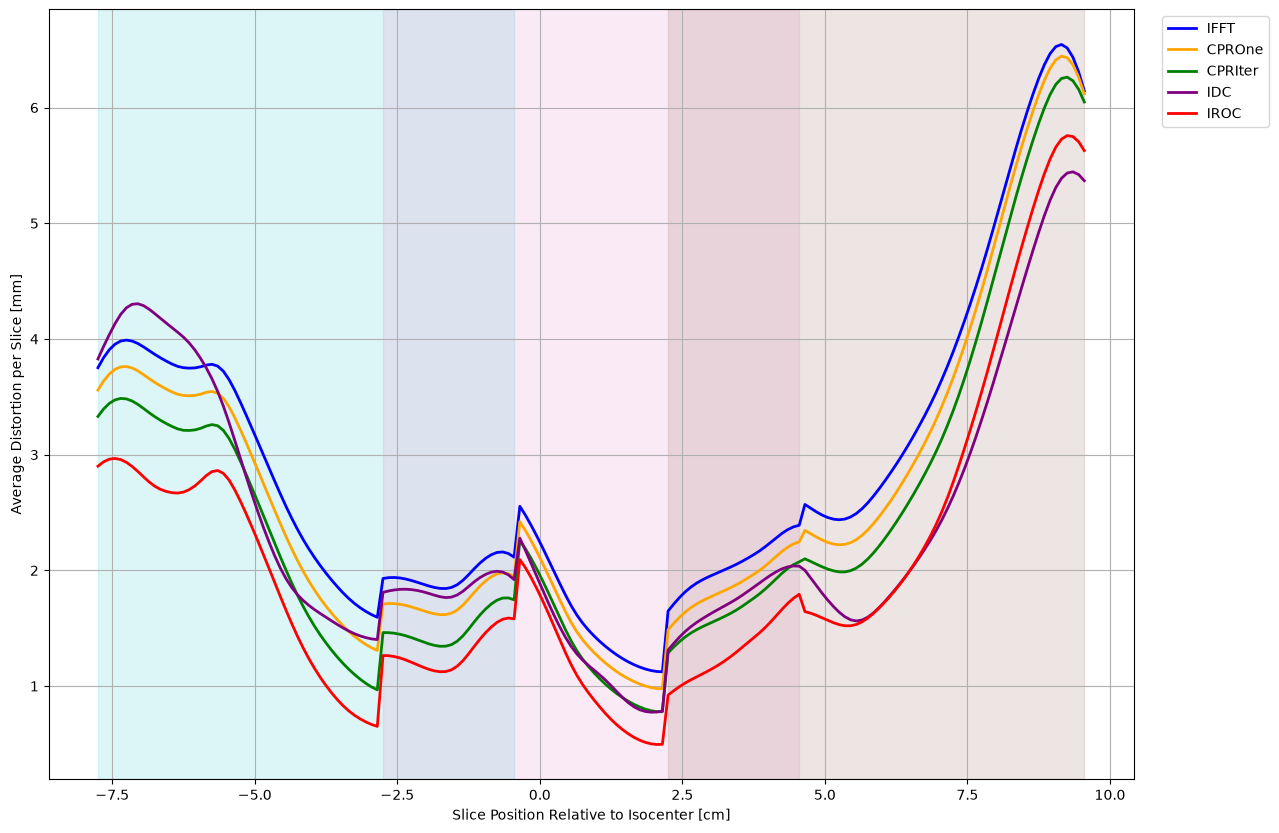


Total Nr Slices:
IFFT       174
CPROne     174
CPRIter    174
IDC        174
IROC       174
dtype: int64

Rank counts in Nr Slices :
      IFFT  CPROne  CPRIter  IDC  IROC
Rank                                  
1        0       0        0   31   143
2        0       0       96   47    31
3        0      50       78   46     0
4       19     124        0   31     0
5      155       0        0   19     0

Rank Expressed in percentages:
        IFFT  CPROne  CPRIter  IDC  IROC
1. [%]     0       0        0   18    82
2. [%]     0       0       55   27    18
3. [%]     0      29       45   26     0
4. [%]    11      71        0   18     0
5. [%]    89       0        0   11     0


In [65]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.read_write as read_write
import src.utils as utils


# ============================================================
# Settings
# ============================================================

# ---- Voxel dimensions ----
voxel_size_mm = 1.0
voxel_size_cm = voxel_size_mm / 10


# ---- Mask ----
radius_in_vox = 83          # Ground Truth Phantom Radius = 83 mm
height_in_vox = 75          # Ground Truth Phantom Height = 75 mm
center = (115, 115, 128)    # Center determined from Ground Truth Phantom Images

mask = utils.create_cylinder_mask(
    volume_shape=(230, 230, 230),
    cylinder_center=center,
    height_in_vox=height_in_vox,
    radius_in_vox=radius_in_vox
).astype(bool)


# ---- Positioning ----
height_in_cm = height_in_vox * voxel_size_cm

isocenter = (
    height_in_cm / 2 - 1
)  # Isocenter relative to Position 2

distance_phantom_positions = 5  # Physical distance between positions [cm]


start = center[2] - (height_in_vox // 2)
end = center[2] + (height_in_vox // 2)


# ============================================================
# Calculate x and y values for each technique
# ============================================================

data = {}

for technique in list_techniques:

    x_values_all = []
    y_values_all = []

    for position in list_position:

        if position not in images[technique]:
            continue

        img = images[technique][position]

        # ----------------------------------------------------
        # Apply mask
        # ----------------------------------------------------
        img = img * mask

        # ----------------------------------------------------
        # Crop
        # ----------------------------------------------------
        img = img[:, :, start:end]

        # ----------------------------------------------------
        # Position-dependent x coordinate
        # ----------------------------------------------------
        if position == "position1":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
                - distance_phantom_positions
            )

        elif position == "position2":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
            )

        elif position == "position3":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
                + distance_phantom_positions
            )

        # ----------------------------------------------------
        # Average magnitude over x/y dimensions
        # ----------------------------------------------------
        magnitude = np.abs(img)

        # Ignore exact zeros in the average
        magnitude[magnitude == 0] = np.nan

        slice_values = np.nanmean(
            magnitude,
            axis=(0, 1)
        )

        # Reverse slice order
        slice_values = slice_values[::-1]

        x_values_all.append(x_values)
        y_values_all.append(slice_values)

    # --------------------------------------------------------
    # Combine the three positions
    # --------------------------------------------------------

    x_all = np.concatenate(x_values_all)
    y_all = np.concatenate(y_values_all)

    # Round to avoid floating-point mismatches
    x_all = np.round(x_all, decimals=6)

    x_combined = np.unique(x_all)

    y_combined = np.array([
        np.mean(y_all[x_all == x])
        for x in x_combined
    ])

    y_smooth = y_combined

    data[technique] = {
        "x": x_combined,
        "y": y_combined,
        "y_smooth": y_smooth
    }


# ============================================================
# Technique colors
# ============================================================

technique_colors = {
    "IFFT": "blue",
    "CPROne": "orange",
    "CPRIter": "green",
    "IDC": "purple",
    "IROC": "red",
}


# ============================================================
# Position ranges
# ============================================================

n_slices = end - start

position_ranges = {

    "position1": (
        -isocenter - distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        - distance_phantom_positions,
    ),

    "position2": (
        -isocenter,

        (n_slices - 1) * voxel_size_cm
        - isocenter,
    ),

    "position3": (
        -isocenter + distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        + distance_phantom_positions,
    ),
}


# ============================================================
# Position background colors
# ============================================================

colors = {
    "position1": "tab:cyan",
    "position2": "tab:pink",
    "position3": "tab:brown"
}


# ============================================================
# Create figure
# ============================================================

fig, ax = plt.subplots(figsize=(14, 10))


# ============================================================
# Background colors for the three positions
# ============================================================

for position, (x_start, x_end) in position_ranges.items():

    ax.axvspan(
        x_start,
        x_end,
        color=colors[position],
        alpha=0.15,
        zorder=0
    )


# ============================================================
# Plot all techniques
# ============================================================

for technique in list_techniques:

    if technique not in data:
        continue

    ax.plot(
        data[technique]["x"],
        data[technique]["y_smooth"],
        linewidth=2,
        color=technique_colors[technique],
        label=technique,
        zorder=3
    )


# ============================================================
# Plot formatting
# ============================================================

ax.set_xlabel(
    "Slice Position Relative to Isocenter [cm]"
)

ax.set_ylabel(
    "Average Distortion per Slice [mm]"
)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(
    zorder=1
)

plt.show()


# ============================================================
# Rank techniques for every slice
# ============================================================

# Create DataFrame:
# rows    = individual slices
# columns = techniques
df_ranking = pd.DataFrame()

for technique in list_techniques:

    if technique not in data:
        continue

    df_ranking[technique] = data[technique]["y_smooth"]


# ------------------------------------------------------------
# Rank techniques at each slice
#
# Lower distortion = better rank
#
# 1 = best
# 2 = second best
# 3 = third best
# etc.
# ------------------------------------------------------------

df_ranks = df_ranking.rank(
    axis=1,
    method="min",
    ascending=True
)


# ============================================================
# Count how many slices each technique achieved each rank
# ============================================================

n_techniques = len(df_ranks.columns)

rank_counts = pd.DataFrame(
    index=range(1, n_techniques + 1),
    columns=df_ranks.columns
)

for rank in range(1, n_techniques + 1):

    rank_counts.loc[rank] = (
        df_ranks == rank
    ).sum(axis=0)


rank_counts = rank_counts.astype(int)

rank_counts.index.name = "Rank"


# ============================================================
# Calculate percentages
# ============================================================

rank_percent = (
    rank_counts
    .div(rank_counts.sum(axis=0), axis=1)
    * 100
)

rank_percent = rank_percent.round(0).astype(int)


# ============================================================
# Add percentage rows below count rows
# ============================================================

rank_percent.index = [
    f"{rank}. [%]"
    for rank in range(1, n_techniques + 1)
]

rank_table = pd.concat([
    rank_counts,
    rank_percent
])


# ============================================================
# Display results
# ============================================================
print(f"\nTotal Nr Slices:\n{rank_counts.sum(axis=0)}")
print("\nRank counts in Nr Slices :")
print(rank_counts)

print("\nRank Expressed in percentages:")
print(rank_percent)


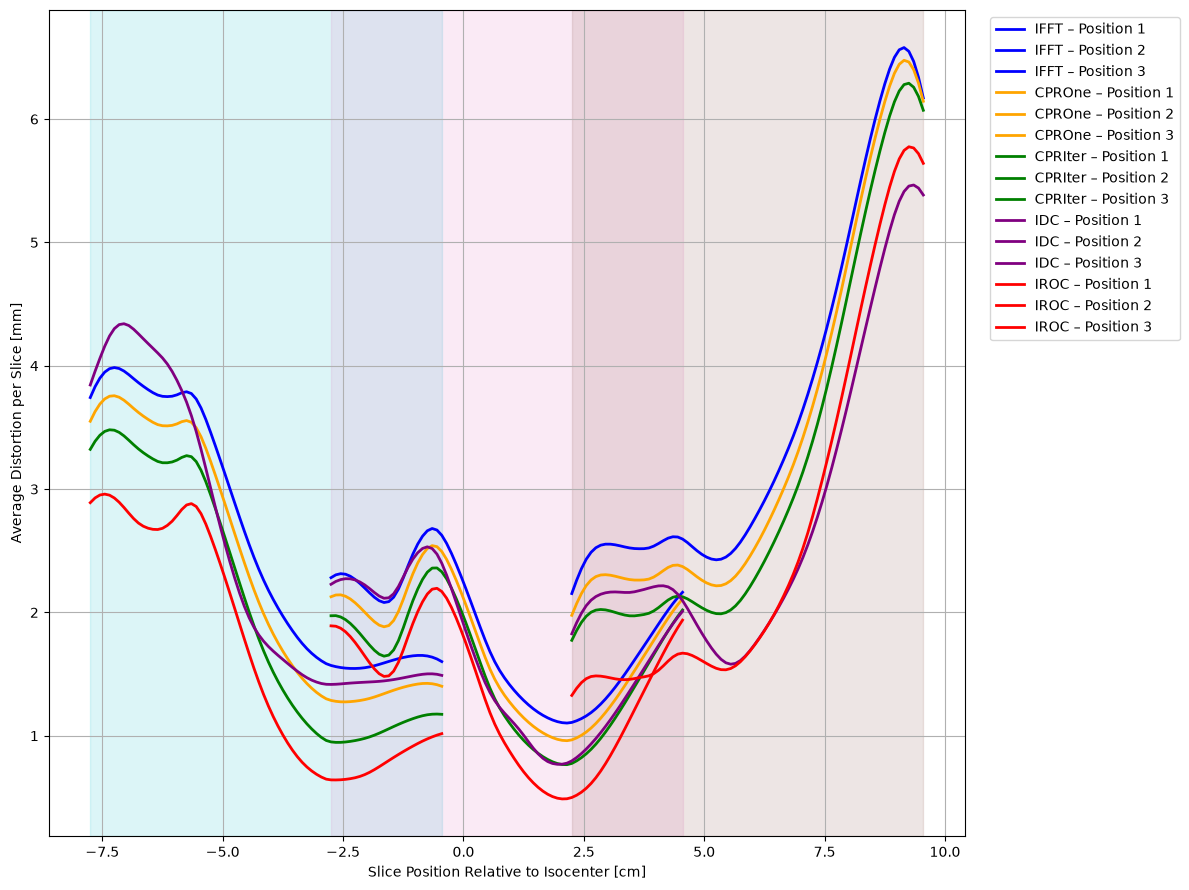


Total Nr Slices:
IFFT       222
CPROne     222
CPRIter    222
IDC        222
IROC       222
dtype: int64

Rank counts:
      IFFT  CPROne  CPRIter  IDC  IROC
Rank                                  
1        0       0        0   32   190
2        0       0      145   45    32
3        0      74       77   71     0
4       30     148        0   44     0
5      192       0        0   30     0

Rank percentages:
        IFFT  CPROne  CPRIter  IDC  IROC
1. [%]     0       0        0   14    86
2. [%]     0       0       65   20    14
3. [%]     0      33       35   32     0
4. [%]    14      67        0   20     0
5. [%]    86       0        0   14     0

Combined ranking table:
        IFFT  CPROne  CPRIter  IDC  IROC
1          0       0        0   32   190
2          0       0      145   45    32
3          0      74       77   71     0
4         30     148        0   44     0
5        192       0        0   30     0
1. [%]     0       0        0   14    86
2. [%]     0       0       65 

In [75]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.read_write as read_write
import src.utils as utils


# ============================================================
# Settings
# ============================================================

# ---- Voxel dimensions ----
voxel_size_mm = 1.0
voxel_size_cm = voxel_size_mm / 10


# ---- Mask ----
radius_in_vox = 82
height_in_vox = 75
center = (115, 115, 128)

mask = utils.create_cylinder_mask(
    volume_shape=(230, 230, 230),
    cylinder_center=center,
    height_in_vox=height_in_vox,
    radius_in_vox=radius_in_vox
).astype(bool)


# ---- Positioning ----
height_in_cm = height_in_vox * voxel_size_cm

isocenter = (
    height_in_cm / 2 - 1
)  # Isocenter relative to Position 2

distance_phantom_positions = 5  # Physical distance between positions [cm]


start = center[2] - (height_in_vox // 2)
end = center[2] + (height_in_vox // 2)


# ============================================================
# Calculate x and y values for each technique and position
# ============================================================

data = {}

for technique in list_techniques:

    data[technique] = {}

    for position in list_position:

        if position not in images[technique]:
            continue

        img = images[technique][position]

        # ----------------------------------------------------
        # Apply mask
        # ----------------------------------------------------
        img = img * mask

        # ----------------------------------------------------
        # Crop
        # ----------------------------------------------------
        img = img[:, :, start:end]

        # ----------------------------------------------------
        # Position-dependent x coordinate
        # ----------------------------------------------------
        if position == "position1":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
                - distance_phantom_positions
            )

        elif position == "position2":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
            )

        elif position == "position3":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
                + distance_phantom_positions
            )

        else:
            continue

        # ----------------------------------------------------
        # Calculate magnitude
        # ----------------------------------------------------
        magnitude = np.abs(img)

        # Ignore exact zeros
        magnitude[magnitude == 0] = np.nan

        # ----------------------------------------------------
        # Average magnitude over x/y dimensions
        # ----------------------------------------------------
        slice_values = np.nanmean(
            magnitude,
            axis=(0, 1)
        )

        # ----------------------------------------------------
        # Reverse slice order
        # ----------------------------------------------------
        slice_values = slice_values[::-1]

        # ----------------------------------------------------
        # Store position-specific data
        # ----------------------------------------------------
        data[technique][position] = {
            "x": x_values,
            "y": slice_values,
        }


# ============================================================
# Technique colors
# ============================================================

technique_colors = {
    "IFFT": "blue",
    "CPROne": "orange",
    "CPRIter": "green",
    "IDC": "purple",
    "IROC": "red",
}


# ============================================================
# Position background colors
# ============================================================

colors = {
    "position1": "tab:cyan",
    "position2": "tab:pink",
    "position3": "tab:brown"
}


# ============================================================
# Position labels
# ============================================================

position_labels = {
    "position1": "Position 1",
    "position2": "Position 2",
    "position3": "Position 3",
}


# ============================================================
# Position ranges
# ============================================================

n_slices = end - start

position_ranges = {

    "position1": (
        -isocenter - distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        - distance_phantom_positions,
    ),

    "position2": (
        -isocenter,

        (n_slices - 1) * voxel_size_cm
        - isocenter,
    ),

    "position3": (
        -isocenter + distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        + distance_phantom_positions,
    ),
}


# ============================================================
# Create figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 9)
)


# ============================================================
# Background colors for the three positions
# ============================================================

for position, (x_start, x_end) in position_ranges.items():

    ax.axvspan(
        x_start,
        x_end,
        color=colors[position],
        alpha=0.15,
        zorder=0
    )


# ============================================================
# Plot all techniques
#
# Each technique:
#   Position 1 -> individual line
#   Position 2 -> individual line
#   Position 3 -> individual line
# ============================================================

for technique in list_techniques:

    if technique not in data:
        continue

    color = technique_colors[technique]

    for position in list_position:

        if position not in data[technique]:
            continue

        x = data[technique][position]["x"]
        y = data[technique][position]["y"]

        ax.plot(
            x,
            y,
            color=color,
            linewidth=2.0,
            label=f"{technique} – {position_labels[position]}",
            zorder=3
        )


# ============================================================
# Plot formatting
# ============================================================

ax.set_xlabel(
    "Slice Position Relative to Isocenter [cm]"
)

ax.set_ylabel(
    "Average Distortion per Slice [mm]"
)

ax.grid(
    zorder=1
)


# ============================================================
# Legend
# ============================================================

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


# ============================================================
# Layout
# ============================================================

plt.tight_layout()

plt.show()



# ============================================================
# Rank techniques for every slice
# ============================================================

# Create DataFrame:
# rows    = individual slices
# columns = techniques
df_ranking = pd.DataFrame()

for technique in list_techniques:

    if technique not in data:
        continue

    df_ranking[technique] = data[technique][position]["y"]

# ============================================================
# Rank techniques for every slice and position
# ============================================================

ranking_data = []

for position in list_position:

    # Get techniques available at this position
    available_techniques = [
        technique
        for technique in list_techniques
        if technique in data
        and position in data[technique]
    ]

    if not available_techniques:
        continue

    # Number of slices
    n_slices = len(
        data[available_techniques[0]][position]["y"]
    )

    # --------------------------------------------------------
    # Create one row per slice
    # --------------------------------------------------------

    for slice_idx in range(n_slices):

        row = {
            "position": position,
            "slice": slice_idx
        }

        for technique in available_techniques:

            row[technique] = (
                data[technique][position]["y"][slice_idx]
            )

        ranking_data.append(row)


# ============================================================
# DataFrame
# ============================================================

df_ranking = pd.DataFrame(ranking_data)

technique_columns = [
    technique
    for technique in list_techniques
    if technique in df_ranking.columns
]

df_values = df_ranking[technique_columns]


# ============================================================
# Rank each slice
#
# Lower distortion = better
# ============================================================

df_ranks = df_values.rank(
    axis=1,
    method="min",
    ascending=True,
    na_option="keep"
)


# ============================================================
# Count ranks
# ============================================================

n_techniques = len(technique_columns)

rank_counts = pd.DataFrame(
    0,
    index=range(1, n_techniques + 1),
    columns=technique_columns
)

for rank in range(1, n_techniques + 1):

    rank_counts.loc[rank] = (
        (df_ranks == rank).sum(axis=0)
    )

rank_counts.index.name = "Rank"


# ============================================================
# Percentages
# ============================================================

valid_counts = df_values.notna().sum(axis=0)

rank_percent = (
    rank_counts
    .div(valid_counts, axis=1)
    * 100
)

rank_percent = rank_percent.round(0).astype(int)

rank_percent.index = [
    f"{rank}. [%]"
    for rank in range(1, n_techniques + 1)
]


# ============================================================
# Combined table
# ============================================================

rank_table = pd.concat([
    rank_counts,
    rank_percent
])


# ============================================================
# Display
# ============================================================

print("\nTotal Nr Slices:")
print(valid_counts)

print("\nRank counts:")
print(rank_counts)

print("\nRank percentages:")
print(rank_percent)

print("\nCombined ranking table:")
print(rank_table)

# Plot Distortion Mean/Std/Max with Distance from Isocenter
Load the distortion-magnitude NIfTI images for each reconstruction technique at the three phantom positions. The images are cropped to the selected slice range, converted to magnitude, andmean distortion per slice is determined. The three phantom positions are then aligned in a common spatial coordinate system and combined. The profiles of all reconstruction techniques are plotted together for comparison.

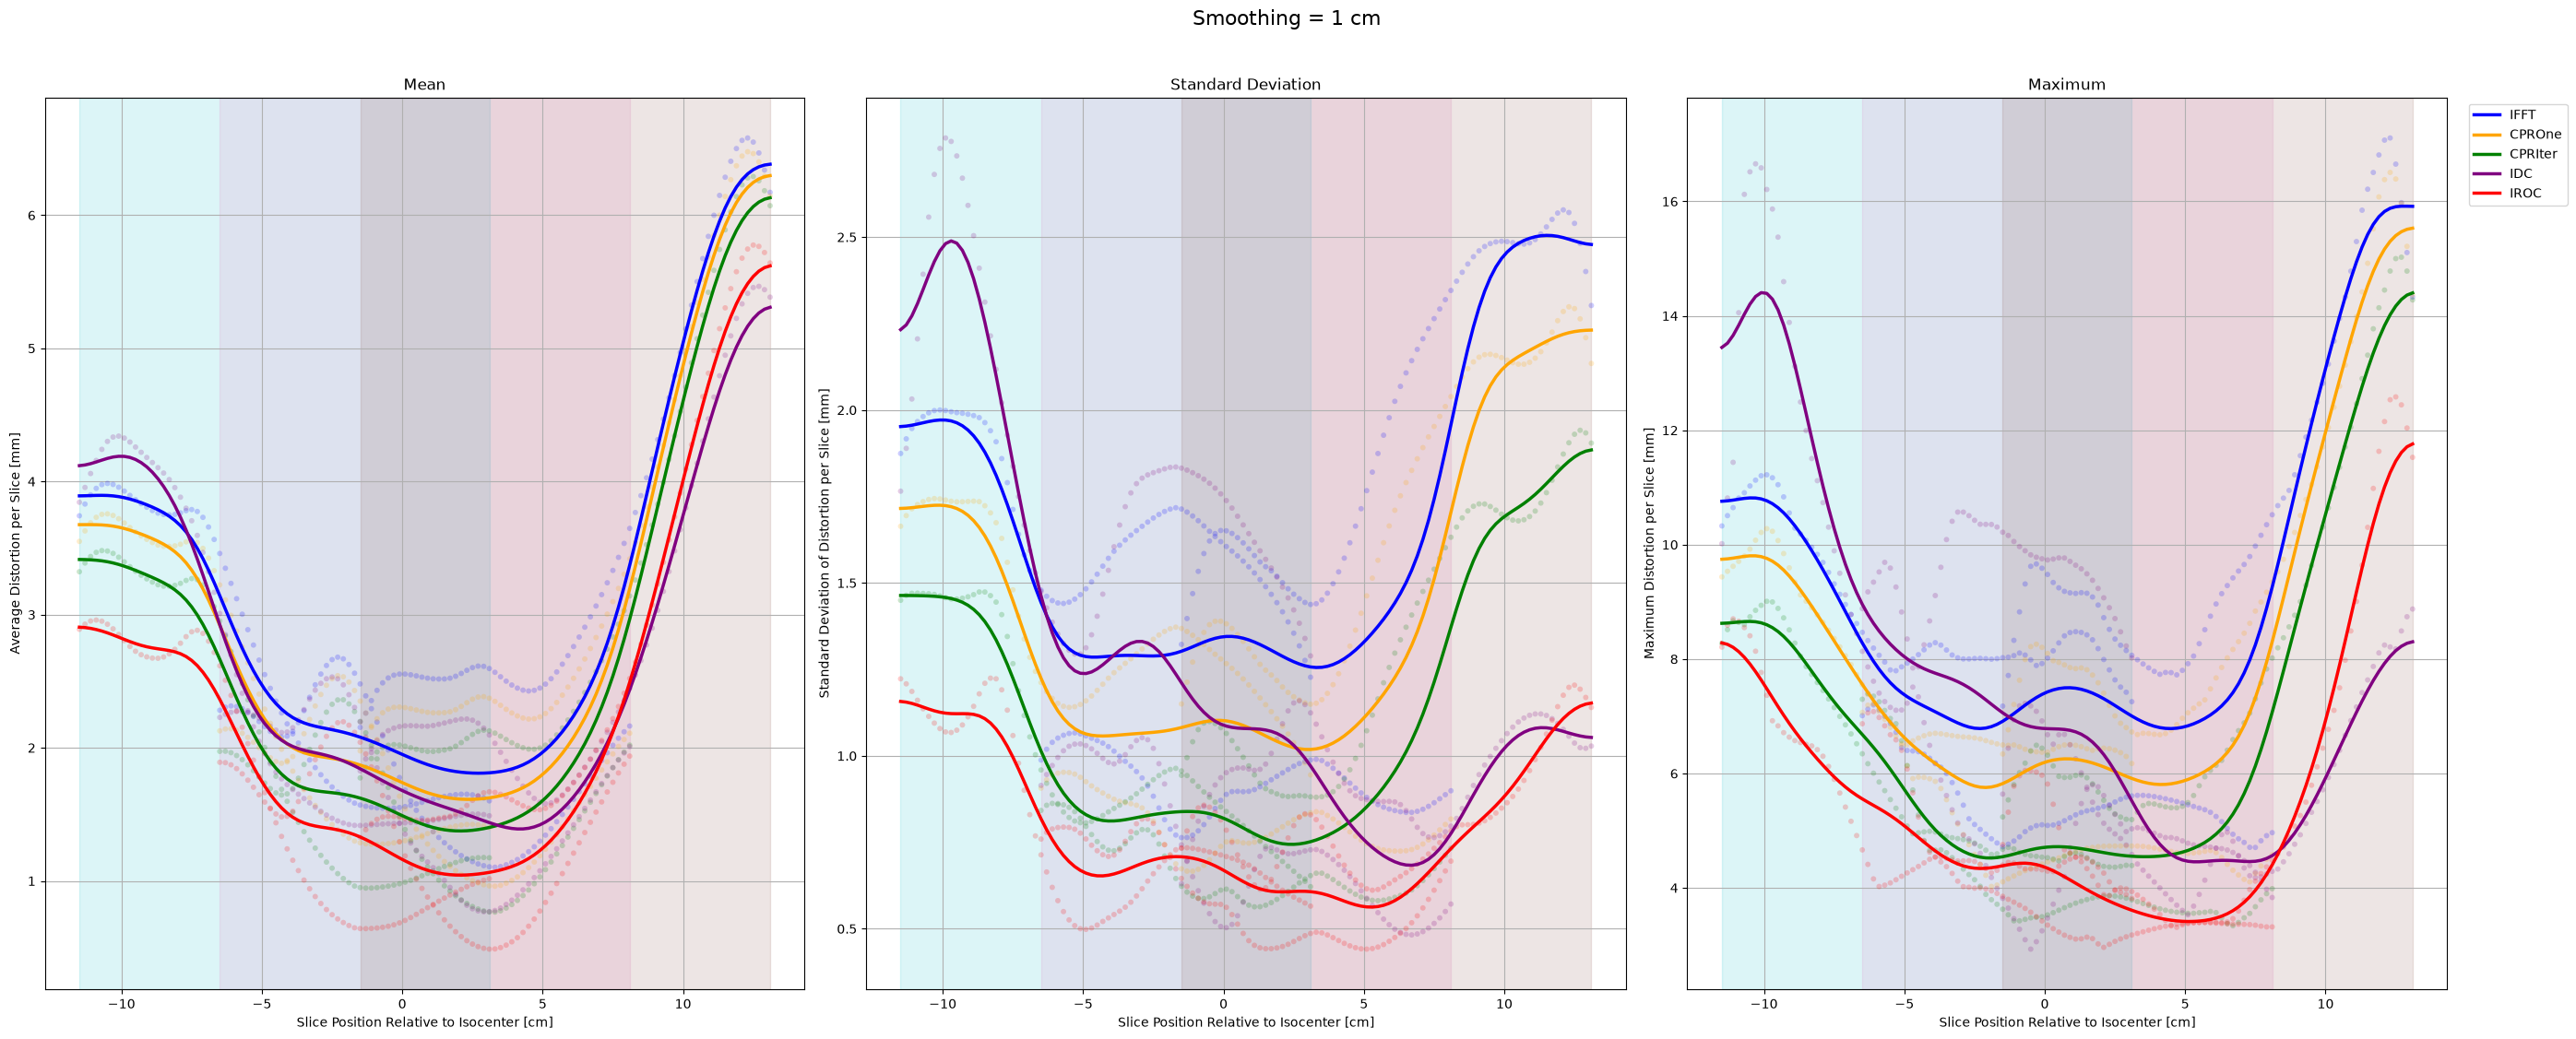

In [68]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

import src.read_write as read_write
import src.utils as utils


# ============================================================
# Settings
# ============================================================

# ---- Voxel dimensions ----
voxel_size_mm = 2
voxel_size_cm = voxel_size_mm / 10


# ---- Smoothing ----
# Gaussian smoothing width in cm.
# 0 = no smoothing
# Higher values = stronger smoothing
smoothing = 1


# ---- Mask ----
radius_in_vox = 82
height_in_vox = 75
center = (115, 115, 128)

mask = utils.create_cylinder_mask(
    volume_shape=(230, 230, 230),
    cylinder_center=center,
    height_in_vox=height_in_vox,
    radius_in_vox=radius_in_vox
).astype(bool)


# ---- Positioning ----
height_in_cm = height_in_vox * voxel_size_cm

isocenter = (
    height_in_cm / 2 - 1
)  # Isocenter relative to Position 2

distance_phantom_positions = 5  # Physical distance between positions [cm]


start = center[2] - (height_in_vox // 2)
end = center[2] + (height_in_vox // 2)


# ============================================================
# Calculate x and y values for each technique
# ============================================================

data = {}

for technique in list_techniques:

    x_values_all = []

    mean_values_all = []
    std_values_all = []
    max_values_all = []

    for position in list_position:

        if position not in images[technique]:
            continue

        img = images[technique][position]

        # ----------------------------------------------------
        # Apply mask
        # ----------------------------------------------------
        img = img * mask

        # ----------------------------------------------------
        # Crop
        # ----------------------------------------------------
        img = img[:, :, start:end]

        # ----------------------------------------------------
        # Position-dependent x coordinate
        # ----------------------------------------------------
        if position == "position1":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
                - distance_phantom_positions
            )

        elif position == "position2":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
            )

        elif position == "position3":

            x_values = (
                np.arange(img.shape[2]) * voxel_size_cm
                - isocenter
                + distance_phantom_positions
            )

        else:
            continue

        # ----------------------------------------------------
        # Calculate magnitude
        # ----------------------------------------------------
        magnitude = np.abs(img)

        # Ignore exact zeros
        magnitude[magnitude == 0] = np.nan

        # ----------------------------------------------------
        # Calculate statistics for every slice
        # ----------------------------------------------------

        mean_values = np.nanmean(
            magnitude,
            axis=(0, 1)
        )

        std_values = np.nanstd(
            magnitude,
            axis=(0, 1)
        )

        max_values = np.nanmax(
            magnitude,
            axis=(0, 1)
        )

        # ----------------------------------------------------
        # Reverse slice order
        # ----------------------------------------------------

        mean_values = mean_values[::-1]
        std_values = std_values[::-1]
        max_values = max_values[::-1]

        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        x_values_all.append(x_values)

        mean_values_all.append(mean_values)
        std_values_all.append(std_values)
        max_values_all.append(max_values)

    # --------------------------------------------------------
    # Combine all positions
    # --------------------------------------------------------

    x_all = np.concatenate(x_values_all)

    mean_all = np.concatenate(mean_values_all)
    std_all = np.concatenate(std_values_all)
    max_all = np.concatenate(max_values_all)

    # Round x values to avoid floating-point mismatches
    x_all = np.round(x_all, decimals=6)

    # --------------------------------------------------------
    # Calculate average at each x position
    # --------------------------------------------------------

    x_average = np.unique(x_all)

    mean_average = np.array([
        np.nanmean(mean_all[x_all == x])
        for x in x_average
    ])

    std_average = np.array([
        np.nanmean(std_all[x_all == x])
        for x in x_average
    ])

    max_average = np.array([
        np.nanmean(max_all[x_all == x])
        for x in x_average
    ])

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    data[technique] = {

        "x_individual": x_all,

        "mean_individual": mean_all,
        "std_individual": std_all,
        "max_individual": max_all,

        "x_average": x_average,

        "mean_average": mean_average,
        "std_average": std_average,
        "max_average": max_average,
    }


# ============================================================
# Technique colors
# ============================================================

technique_colors = {
    "IFFT": "blue",
    "CPROne": "orange",
    "CPRIter": "green",
    "IDC": "purple",
    "IROC": "red",
}


# ============================================================
# Position ranges
# ============================================================

n_slices = end - start

position_ranges = {

    "position1": (
        -isocenter - distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        - distance_phantom_positions,
    ),

    "position2": (
        -isocenter,

        (n_slices - 1) * voxel_size_cm
        - isocenter,
    ),

    "position3": (
        -isocenter + distance_phantom_positions,

        (n_slices - 1) * voxel_size_cm
        - isocenter
        + distance_phantom_positions,
    ),
}


# ============================================================
# Position background colors
# ============================================================

colors = {
    "position1": "tab:cyan",
    "position2": "tab:pink",
    "position3": "tab:brown"
}


# ============================================================
# Create 1 × 3 subplot
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(28, 11),
    sharex=True
)


# ============================================================
# Plot definitions
# ============================================================

plot_types = [
    {
        "key": "mean",
        "title": "Mean",
        "ylabel": "Average Distortion per Slice [mm]"
    },
    {
        "key": "std",
        "title": "Standard Deviation",
        "ylabel": "Standard Deviation of Distortion per Slice [mm]"
    },
    {
        "key": "max",
        "title": "Maximum",
        "ylabel": "Maximum Distortion per Slice [mm]"
    }
]


# ============================================================
# Plot each subplot
# ============================================================

for ax, plot_type in zip(axes, plot_types):

    key = plot_type["key"]

    # --------------------------------------------------------
    # Background colors
    # --------------------------------------------------------

    for position, (x_start, x_end) in position_ranges.items():

        ax.axvspan(
            x_start,
            x_end,
            color=colors[position],
            alpha=0.15,
            zorder=0
        )

    # --------------------------------------------------------
    # Plot all techniques
    # --------------------------------------------------------

    for technique in list_techniques:

        if technique not in data:
            continue

        color = technique_colors[technique]

        # ----------------------------------------------------
        # Individual slice measurements
        # ----------------------------------------------------

        ax.scatter(
            data[technique]["x_individual"],
            data[technique][f"{key}_individual"],
            s=18,
            color=color,
            alpha=0.2,
            edgecolors="none",
            zorder=2
        )

        # ----------------------------------------------------
        # Average line
        # ----------------------------------------------------

        x_average = data[technique]["x_average"]
        y_average = data[technique][f"{key}_average"]

        # ----------------------------------------------------
        # Apply Gaussian smoothing to averaged curve
        # ----------------------------------------------------
        if smoothing > 0:

            # Determine spacing between x points
            dx = np.mean(np.diff(x_average))

            # Convert smoothing from cm to number of samples
            sigma_pixels = smoothing / dx

            y_plot = gaussian_filter1d(
                y_average,
                sigma=sigma_pixels
            )

        else:

            # No smoothing
            y_plot = y_average

        # ----------------------------------------------------
        # Plot averaged / smoothed curve
        # ----------------------------------------------------

        ax.plot(
            x_average,
            y_plot,
            linewidth=2.5,
            color=color,
            label=technique,
            zorder=4
        )

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_title(
        plot_type["title"]
    )

    ax.set_xlabel(
        "Slice Position Relative to Isocenter [cm]"
    )

    ax.set_ylabel(
        plot_type["ylabel"]
    )

    ax.grid(
        zorder=1
    )


# ============================================================
# Single legend
# ============================================================

axes[-1].legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


# ============================================================
# Add smoothing information at top
# ============================================================

fig.suptitle(
    f"Smoothing = {smoothing} cm",
    fontsize=16,
    y=1.02
)


# ============================================================
# Layout
# ============================================================

plt.tight_layout()

plt.show()

In [70]:
# ============================================================
# Ranking tables
# ============================================================

def create_rank_table(data, list_techniques, metric):

    # --------------------------------------------------------
    # Create DataFrame
    # rows    = individual slices
    # columns = techniques
    # --------------------------------------------------------

    df = pd.DataFrame()

    for technique in list_techniques:

        if technique not in data:
            continue

        df[technique] = data[technique][
            f"{metric}_individual"
        ]

    # --------------------------------------------------------
    # Rank techniques for every slice
    # Lower distortion = better
    # --------------------------------------------------------

    ranks = df.rank(
        axis=1,
        method="min",
        ascending=True
    )

    # --------------------------------------------------------
    # Count ranks
    # --------------------------------------------------------

    n_techniques = len(ranks.columns)

    counts = pd.DataFrame(
        index=range(1, n_techniques + 1),
        columns=ranks.columns
    )

    for rank in range(1, n_techniques + 1):

        counts.loc[rank] = (
            ranks == rank
        ).sum(axis=0)

    counts = counts.astype(int)

    counts.index.name = "Rank"

    # --------------------------------------------------------
    # Percentages
    # --------------------------------------------------------

    percentages = (
        counts
        .div(counts.sum(axis=0), axis=1)
        * 100
    )

    percentages = percentages.round(0).astype(int)

    percentages.index = [
        f"{rank} [%]"
        for rank in range(1, n_techniques + 1)
    ]

    # --------------------------------------------------------
    # Combine counts + percentages
    # --------------------------------------------------------

    table = pd.concat([
        counts,
        percentages
    ])

    return table


# ============================================================
# Three ranking tables
# ============================================================

rank_table_mean = create_rank_table(
    data,
    list_techniques,
    "mean"
)

rank_table_std = create_rank_table(
    data,
    list_techniques,
    "std"
)

rank_table_max = create_rank_table(
    data,
    list_techniques,
    "max"
)


# ============================================================
# Display the three tables
# ============================================================

print("\n================ MEAN ================\n")
print(rank_table_mean)

print("\n================ STD ================\n")
print(rank_table_std)

print("\n================ MAX ================\n")
print(rank_table_max)


================ MEAN ================

       IFFT  CPROne  CPRIter  IDC  IROC
1         0       0        0   32   190
2         0       0      145   45    32
3         0      74       77   71     0
4        30     148        0   44     0
5       192       0        0   30     0
1 [%]     0       0        0   14    86
2 [%]     0       0       65   20    14
3 [%]     0      33       35   32     0
4 [%]    14      67        0   20     0
5 [%]    86       0        0   14     0

================ STD ================

       IFFT  CPROne  CPRIter  IDC  IROC
1         0       0       13   27   182
2         0       0      128   54    40
3         0     101       81   40     0
4        69     121        0   32     0
5       153       0        0   69     0
1 [%]     0       0        6   12    82
2 [%]     0       0       58   24    18
3 [%]     0      45       36   18     0
4 [%]    31      55        0   14     0
5 [%]    69       0        0   31     0

================ MAX ================
